# 📈 11-00 · 时间序列基础与平稳性

> 目标：把「时间序列分析」的第一性原理打牢。学完本篇你能——
> ① 手写 **ACF / PACF / 差分 / ADF / Ljung-Box / Yule-Walker** 六大工具，并说清每一步在做什么；
> ② 从随机游走一步步推出方差 $\\text{Var}(y_t)=t\\sigma^2$，并解释"为什么非平稳不能直接建模"；
> ③ 用 **ADF 与 KPSS 互补检验** 判断序列平稳性，能演示**伪回归**陷阱并说明季节差分 $y_t-y_{t-m}$。

> 📍 **主线位置**：前一篇《数学与机器学习基础》提供工具（OLS/极大似然/检验）→ 本篇《基础与平稳性》解决"数据能不能直接建模" → 后一篇《01 ARMA 与 ARIMA》在平稳序列上建立第一个正经预测模型。
> 本篇是整章的地基：**建模前的第一步永远是问"它平稳吗？"**。

> 🧩 **生活化类比**：平稳性 = "规律稳定可外推"。心电图是平稳的（波峰波谷规律重复），股价长期是"随机游走"（今天与昨天的差纯随机）——前者能预测，后者难。分析时间序列的第一步永远是：**它平稳吗？**

## 核心概念

### (a) 🗂️ 一张图看懂本篇主线

```mermaid
flowchart TB
    Node1["🧠 时间序列：构成 趋势+季节+噪声"]
    Node2["📐 平稳性：均值/方差恒定，协方差只依赖滞后"]
    Node3["🔍 ACF / PACF：自相关指纹"]
    Node4["⚪ 白噪声与 Ljung-Box 检验"]
    Node5["✂️ 差分：一阶/季节差分 y_t - y_{t-m}"]
    Node6["🧪 ADF 单位根检验（H0: 有单位根）"]
    Node7["🔁 KPSS 检验（H0: 趋势平稳）"]
    Node8["⚠️ 伪回归：两随机游走 OLS 假显著"]
    Node1 --> Node2
    Node2 --> Node3
    Node3 --> Node4
    Node2 --> Node5
    Node5 --> Node6
    Node6 --> Node7
    Node6 --> Node8
```

### (b) 七个必须带走的概念

- **构成**：$y_t = T_t + S_t + C_t + \\epsilon_t$（加法）或 $y_t = T_t \\cdot S_t \\cdot C_t \\cdot \\epsilon_t$（乘法）。分析顺序：**先分解/差分去掉非平稳成分，再对平稳残差建模**。
- **平稳性（弱平稳）**：① 均值恒定 $E[y_t]=\\mu$；② 方差恒定；③ 协方差只依赖滞后 $k$：$\\gamma(k)=\\text{Cov}(y_t, y_{t-k})$。非平稳的均值/方差在漂移，拟合出来的是"历史平均"而非"动态规律"。
- **ACF/PACF**：$\\rho(k)=\\gamma(k)/\\gamma(0)$ 是与滞后 $k$ 的自相关；PACF 剔除中间滞后影响后的"纯相关"。95% 置信带 $\\approx \\pm 1.96/\\sqrt{n}$。
- **白噪声**：$\\epsilon_t \\sim \\text{iid}(0,\\sigma^2)$，ACF 全为 0 —— 模型诊断的"理想终点"。

### (c) 四个检验/操作工具

- **差分**：一阶差分去趋势/随机游走；季节差分 $y_t-y_{t-m}$ 去周期。
- **ADF**：$\\Delta y_t = \\alpha + \\beta t + \\gamma y_{t-1} + \\sum \\phi_k \\Delta y_{t-k}$，检验 $\\gamma=0$，t 越负越拒绝。
- **KPSS**：原假设**趋势平稳**，与 ADF（原假设有单位根）互补：两者同拒/同不拒都值得警惕。
- **伪回归**：两个独立随机游走做 OLS 也常"显著"——统计推断的前提是平稳。

## 0. 主线地图

```
看图（趋势/季节/噪声？）
   │
   ▼
平稳吗？ ──ADF / KPSS 双检──► 非平稳
   │                              │
   ▼                            差分（一阶 / 季节）或分解
平稳                            │
   │                              ▼
   ▼                          再检验 ACF/PACF 是否白噪声
ACF/PACF 定阶（识指纹）
   │
   ▼
后一篇 01-ARMA与ARIMA：建模 + 预测
```

> 本篇终点：对陌生序列流利回答——"先画图，再 ADF/KPSS 双检，非平稳就差分，差分后看 ACF/PACF 是否白噪声，然后才能进 01 篇建模"。

### 0.1 历史背景：从"为什么股票预测总失败"讲起

- 1950s：电子计算机让大规模自相关计算成为可能；统计学家发现很多经济序列**方差随时间增长**（典型如股价），直觉上"规律"在漂移。
- **1979 年 Dickey & Fuller**：提出 ADF 单位根检验，给"平稳 vs 非平稳"一个可判别的统计量（本篇 §7）。这是时间序列计量经济学最常用的检验之一。
- 同期 **Box & Jenkins**（1970）建立 ARIMA 方法论：识别 → 估计 → 诊断 → 预测。第一步识别就依赖 ACF/PACF 与平稳性判断。
- **1992 年 KPSS（Kwiatkowski-Phillips-Schmidt-Shin）**：把原假设反过来（趋势平稳），与 ADF 形成"互证"组合——这也是面试里"为什么同时做 ADF 和 KPSS"的答案。
- **一句话记忆**：先问"数据规律会不会漂移"（平稳性）→ 会就差分/分解（本篇工具）→ 不会就建模（01 篇起）。

## 1. 时间序列的构成：加法 vs 乘法

$$y_t = T_t + S_t + C_t + \\epsilon_t \\quad(\\text{加法}) \\qquad
y_t = T_t \\cdot S_t \\cdot C_t \\cdot \\epsilon_t \\quad(\\text{乘法})$$

- $T$ 趋势（长期方向）、$S$ 季节（固定周期）、$C$ 周期（非固定，如经济周期）、$\\epsilon$ 噪声
- 分析顺序：**先分解/差分把非平稳成分去掉，再对平稳残差建模**（本篇 §2 的差分就是最简"去成分"）。

### 1.1 加法还是乘法：看季节振幅

- **什么时候用加法**：季节振幅稳定（不随水平变化）——如室温序列。
- **什么时候用乘法**：振幅随水平放大（如零售额随规模增长）——或用对数转成加法：$\\ln y_t = \\ln T_t + \\ln S_t + \\ln \\epsilon_t$。
- 判断技巧：画图看**峰谷差是否随水平走**——随水平放大 → 乘法 / 对数。

> 面试一句话：加法=各成分独立相加；乘法=成分按比例作用；乘法可经对数转加法统一处理。

## 2. 平稳性：两种定义 + 随机游走方差推导

### 2.1 强平稳 vs 弱平稳

| | 强平稳（严格） | 弱平稳（实用） |
|---|---|---|
| 定义 | 任意时间平移下联合分布不变 | ① 均值恒定；② 方差恒定；③ 协方差只依赖滞后 |
| 可验证性 | 几乎不可验证 | 可检验（ACF/ADF/KPSS） |
| 建模用 | 理论 | **绝大多数模型的前提** |

**为什么必须平稳**：统计建模需要"规律不随时间变"；非平稳序列的均值/方差本身在漂移，拟合出来的是"历史平均"而非"动态规律"。

### 2.2 随机游走为什么非平稳：方差推导（重点）

设 $y_t = y_{t-1} + \\epsilon_t$，$\\epsilon_t \\sim \\text{iid}(0, \\sigma^2)$，$y_0 = 0$。迭代展开：

$$y_t = y_0 + \\epsilon_1 + \\epsilon_2 + \\cdots + \\epsilon_t = \\sum_{j=1}^{t} \\epsilon_j$$

因为 $\\epsilon_j$ 相互独立，方差直接相加：

$$\\text{Var}(y_t) = \\text{Var}\\Big(\\sum_{j=1}^{t} \\epsilon_j\\Big) = \\sum_{j=1}^{t} \\text{Var}(\\epsilon_j) = t\\sigma^2$$

**手算表（σ=1）**：

| t | Var(y_t) | 直觉 |
|---|---|---|
| 1 | $1\\sigma^2 = 1$ | 只含 1 个噪声 |
| 2 | $2\\sigma^2 = 2$ | 两个噪声叠加 |
| 3 | $3\\sigma^2 = 3$ | 三个噪声叠加 |
| 4 | $4\\sigma^2 = 4$ | 四个噪声叠加 |

方差随 t **线性增长** → 序列越来越"散" → 非平稳。但它的**一阶差分是白噪声（平稳）**。

> 面试高频三连问：
> 1. 随机游走平稳吗？—— 不平稳（方差随 t 增长）。
> 2. 差分后呢？—— 一阶差分是白噪声，平稳。
> 3. 为什么不能直接对随机游走做 OLS？—— 残差不平稳 → 伪回归（§9），t 检验失效。

## 3. ACF 与 PACF：自相关的指纹

- **ACF（自相关函数）**：$\\rho(k) = \\dfrac{\\gamma(k)}{\\gamma(0)}$ —— 与滞后 $k$ 自身的相关性
- **PACF（偏自相关）**：剔除中间滞后影响后，$y_t$ 与 $y_{t-k}$ 的纯相关
- 用途：识别模型阶数（AR 的 PACF 截尾、MA 的 ACF 截尾——01 篇详讲）

$$\\hat\\rho(k) = \\frac{\\sum_{t} (y_t - \\bar y)(y_{t-k} - \\bar y)}{\\sum_{t} (y_t - \\bar y)^2}$$

**95% 置信带**：$\\pm 1.96 / \\sqrt{n}$——越界提示存在显著自相关。

### 3.1 手算 ACF 小例

对 $x=[1,2,3,2,1]$，$\\bar x=1.8$，去中心后 $[-0.8,0.2,1.2,0.2,-0.8]$。

分母：$\\sum(x-\\bar x)^2 = 0.64+0.04+1.44+0.04+0.64 = 2.8$。

分子 $\\rho(1)$：$(0.2)(-0.8)+(1.2)(0.2)+(0.2)(1.2)+(-0.8)(0.2) = -0.16+0.24+0.24-0.16 = 0.16$

$$\\hat\\rho(1) = 0.16/2.8 \\approx 0.057$$

> 手算要点：**ACF 是"错位乘积之和 / 总平方和"**——错位对齐后做点积，减去均值避免水平偏移污染。

## 4. Yule-Walker 方程：从自相关反推参数（重点）

AR(1)：$y_t = \\varphi y_{t-1} + \\epsilon_t$。两边乘 $y_{t-k}$ 取期望：

$$\\gamma(k) = \\varphi \\gamma(k-1) + E[\\epsilon_t y_{t-k}]$$

当 $k=0$：$\\gamma(0) = \\varphi \\gamma(1) + \\sigma^2$；当 $k\\ge 1$：$\\gamma(k) = \\varphi \\gamma(k-1)$（噪声与过去无关）。

解出：
$$\\gamma(0) = \\frac{\\sigma^2}{1 - \\varphi^2}, \\qquad \\rho(k) = \\frac{\\gamma(k)}{\\gamma(0)} = \\varphi^k$$

### 4.1 手算 φ=0.8 的理论 ACF

**手算（φ=0.8）**：$\\rho(1)=0.8,\\ \\rho(2)=0.64,\\ \\rho(3)=0.512,\\ \\rho(4)=0.4096$——指数衰减。
若 $\\sigma^2=1$：$\\gamma(0)=1/(1-0.64)=2.777\\ldots$，即 $\\text{Var}(y_t)=2.78$。

**Yule-Walker 方程组（AR(2) 推广）**：$\\gamma(k) = \\phi_1 \\gamma(k-1) + \\phi_2 \\gamma(k-2)$，写成矩阵 $\\boldsymbol{\\Gamma}\\boldsymbol{\\phi} = \\boldsymbol{\\gamma}$。01 篇会手解 2×2 例。

> 面试一句话：**YW 从自相关矩阵反解 AR 系数**——$\\rho(1)=\\varphi$ 就是 AR(1) 系数的一致估计。

## 5. ψ-权重：AR 的 MA(∞) 表示（衔接 01 篇预测区间）

AR(1) 可反复代入改写成"过去噪声的加权和"（MA(∞) 表示）：

$$y_t = \\epsilon_t + \\varphi \\epsilon_{t-1} + \\varphi^2 \\epsilon_{t-2} + \\cdots = \\sum_{j=0}^{\\infty} \\psi_j \\epsilon_{t-j}, \\qquad \\psi_j = \\varphi^j$$

- **ψ-权重** 衡量"t−j 期噪声对今天的影响"，影响指数衰减。
- 与 ACF 的关系：$\\gamma(0) = \\sigma^2 \\sum_{j=0}^{\\infty} \\psi_j^2 = \\sigma^2/(1-\\varphi^2)$，与 §4 一致。

### 5.1 ψ-权重与预测区间（01 篇预告）

- **预测区间**：h 步预测误差方差 $= \\sigma^2 \\sum_{j=0}^{h-1} \\psi_j^2$——"越远越不确定"的数学来源。
- 例：φ=0.8 时 h=1,2,3 的方差比 $1,\\ 1.64,\\ 2.02$，区间宽 $\\propto \\sqrt{\\sum_{j<h}\\psi_j^2}$。

> 面试一句话：AR 模型 = 一阶线性差分方程，解得 ψ 权重 $\\varphi^j$；预测方差随步长按 $\\sum_{j<h}\\varphi^{2j}$ 累积。

## 6. 白噪声与 Ljung-Box 检验

**白噪声**：$\\epsilon_t \\sim \\text{iid}(0, \\sigma^2)$，ACF 全为 0 —— 模型诊断的"理想终点"。

Ljung-Box 检验（1978）：检验前 h 阶 ACF 是否联合为 0：
$$Q = n(n+2)\\sum_{k=1}^{h} \\frac{\\hat\\rho_k^2}{n-k} \\sim \\chi^2_h$$

- $Q$ 大（p 小）→ 拒绝"无自相关" → 信息没提取干净，模型需要加结构。
- $Q$ 小（p 大）→ 无法拒绝"残差是白噪声" → 模型合格。

## 7. ADF 单位根检验（完整版）

**单位根**：若 $y_t = \\rho y_{t-1} + \\epsilon_t$ 中 $\\rho = 1$ → 非平稳（随机游走）。

ADF（Augmented Dickey-Fuller）回归含滞后差分项，处理残差自相关：

$$\\Delta y_t = \\alpha + \\beta t + \\gamma y_{t-1} + \\sum_{k=1}^{p} \\phi_k \\Delta y_{t-k} + e_t$$

- 原假设 $H_0: \\gamma = 0$（有单位根，非平稳）
- 统计量 $t = \\hat\\gamma / \\text{se}(\\hat\\gamma)$，**越负越拒绝**（拒绝 = 平稳）
- 临界值（带常数、无趋势，5%）≈ **−2.86**；带趋势 ≈ −3.41
- 滞后阶 p 用 AIC/BIC 选（01 篇细讲）；本篇实验 p 取固定值对照 

### 7.1 手写思路：简化 ADF

**手算思路**：OLS 拟合回归，取 $y_{t-1}$ 系数的 t 统计量 $t=\\hat\\gamma/\\text{se}(\\hat\\gamma)$。

教学版简化成 $\\Delta y_t = \\alpha + \\gamma y_{t-1}$（不滞后差分项），符号与量级与 statsmodels 一致、方便手验。

> 面试一句话：**ADF = 回归 $\Delta y_t$ 于 $y_{t-1}$，看系数是否显著为负**；加滞后差分项是为了吸收残差自相关。

## 8. KPSS 检验：把原假设反过来（互补）

KPSS（Kwiatkowski-Phillips-Schmidt-Shin, 1992）检验**趋势平稳**：
$$H_0:\\ y_t \\text{ 趋势平稳（确定性趋势 + 平稳扰动）} \\qquad H_1:\\ \\text{有单位根}$$

模型：$y_t = \\beta t + r_t + \\epsilon_t$，其中 $r_t = r_{t-1} + u_t$，检验 $\\text{Var}(u_t)=0$。统计量基于部分和平方：
$$\\text{KPSS} = \\frac{1}{T^2 \\hat\\sigma^2} \\sum_{t=1}^{T} S_t^2, \\qquad S_t = \\sum_{i=1}^{t} \\hat e_i$$

### 8.1 ADF × KPSS 四象限决策表

| 组合 | 含义 |
|---|---|
| ADF 拒绝 + KPSS 不拒 | 结论一致：平稳 ✅ |
| ADF 不拒 + KPSS 拒绝 | 结论一致：非平稳（有单位根）|
| **ADF 拒绝 + KPSS 拒绝** | 矛盾：可能序列太短 / 有结构突变 / 结论存疑 |
| **ADF 不拒 + KPSS 不拒** | 矛盾：数据信息不足，多看 ACF/图 |

> 面试一句话：**ADF 与 KPSS 是互补对——一个假设有单位根，一个假设平稳；两者结论一致才可信**。

## 9. 伪回归：两个随机游走也能"显著相关"

**伪回归（spurious regression）**：两个相互独立的非平稳序列做 OLS，$t$ 检验常"显著"——因为两者都在漂移，OLS 会把"同向漂移"当成相关。

Granger & Newbold (1974)：两独立随机游走回归，**约 75% 的情况 $|t|>2$ 拒绝"无关"**，R² 也常虚高。

**为什么**：非平稳序列的残差不平稳，OLS 的 $\\text{se}(\\hat\\beta)$ 被严重低估 → $t$ 统计量虚高 → 假显著。

> 面试一句话：**伪回归 = 两个各自漂移的序列"同向而行"被误读为因果**；解法：先差分/去趋势，或做协整分析（本篇不展开，知道"先平稳化"即可）。

### 9.1 伪回归的直觉：为什么"同漂移"会被当成相关

想象两辆车各自挂挡漂移（随机游走），你若只看它们是否"同步"，会发现它们常朝同一方向——但这与彼此的"因果关系"无关，纯粹是各自惯性。

- 非平稳残差 → OLS 标准误被低估 → $t$ 虚高
- 即便 R² 高达 0.9 也可能是假的（对照实验会看到）

> 解法永远先平稳化：差分/去趋势后再回归，$t$ 检验恢复 5% 名义水平（实验 9 对照部分直接验证）。

## 10. 季节差分：去固定周期

**季节差分**：$\\Delta_m y_t = y_t - y_{t-m}$，其中 $m$ 是季节周期（月度数据 m=12，小时数据 m=24）。它把"同周期位置的差值"提取出来，可消除固定周期成分（加法情形）：

$$\\Delta_{24} y_t = y_t - y_{t-24} = \\Delta_{24} T_t + \\Delta_{24} S_t + \\Delta_{24}\\epsilon_t$$

若 $S_t$ 严格以 24 为周期（$S_t=S_{t-24}$），则 $\\Delta_{24}S_t=0$ → 季节被完全去掉。

### 10.1 结构突变与差分选择

**结构突变**（一句话）：若序列在某时点均值/趋势跳变（如政策出台），ADF/KPSS 会"误判"——因为检验把突变当成了单位根。处理：加入结构突变虚拟变量或分段建模。

> 面试一句话：**一阶差分去趋势、季节差分去周期**；两者可叠加（如 $\\Delta\\Delta_{12}$），但过度差分会让信噪比下降。

| 成分 | 处理 | 例 |
|---|---|---|
| 趋势 | 一阶差分 | 股价随机游走 |
| 固定周期 | 季节差分 $\\Delta_m$ | 月度零售、小时流量 |
| 两者都有 | 先一阶再季节差分 | 有趋势的夏令时序列 |

## 数字敏感度与易错点

1. **$\\rho(0)\\equiv 1$**：ACF 数组第一位永远是 1，实现时别把 `x[:-0]` 当成"取全部"——`x[:-0]` 是空数组。
2. **强平稳 ≠ 弱平稳**：强平稳蕴含弱平稳，反之不然；建模只需弱平稳。
3. **ADF 的滞后阶**：滞后太少残差自相关未吸收、太多自由度浪费——用 AIC/BIC 选，别拍脑袋。
4. **ADF/KPSS 结论矛盾**：不是 bug，是"序列太短 / 有结构突变 / 数据信息不足"的信号，多看 ACF 与图。
5. **伪回归**：非平稳序列 OLS 的 $t$ 检验虚高（>50% 假显著），**先平稳化再回归**。
6. **季节差分别乱用**：$y_t-y_{t-m}$ 只去固定周期；叠加一阶+季节差分会损失样本，慎用。
7. **置信带是逐点近似**：$\\pm1.96/\\sqrt{n}$ 对每个滞后单独成立，多重比较会放大假阳性。
8. **差分次数要克制**：差分是"去成分"不是"越多越好"；过度差分让残差方差增大、信噪比下降。

### 一句话总结本篇

```
平稳性 ──► 画图 + ADF/KPSS 双检
   │
   ├─ 非平稳 ──► 一阶差分 / 季节差分 ──► 再检验
   │
   ▼
平稳 ──► ACF/PACF 定阶 ──► 01 篇 ARMA/ARIMA 建模预测
```

**五件必须带走的事**：① 随机游走方差 $t\\sigma^2$ 线性增长；② Yule-Walker 给出 $\\rho(k)=\\varphi^k$；③ ψ-权重把 AR 变成噪声加权记忆；④ ADF/KPSS 互补双检；⑤ 伪回归靠先平稳化解。

## 面试速答（30 秒背诵版）

- **平稳性三条件**：均值/方差恒定、协方差只依赖滞后
- **随机游走非平稳**：$y_t=\\sum_{j\\le t}\\epsilon_j$，$\\text{Var}(y_t)=t\\sigma^2$；一阶差分变白噪声
- **ACF/PACF**：$\\rho(k)=\\gamma(k)/\\gamma(0)$；AR→PACF 截尾，MA→ACF 截尾；置信带 $\\pm1.96/\\sqrt n$
- **ADF**：$\\Delta y_t=\\alpha+\\beta t+\\gamma y_{t-1}+\\sum\\phi_k\\Delta y_{t-k}$，检验 $\\gamma=0$，t 越负越拒绝；5% 临界 ≈ −2.86
- **KPSS**：原假设趋势平稳，与 ADF 互补；两者一致才可信
- **伪回归**：两独立随机游走 OLS 假显著比例 >> 5%；解法是先平稳化
- **Ljung-Box**：$Q=n(n+2)\\sum \\hat\\rho_k^2/(n-k)\\sim\\chi^2_h$，残差 p>0.05 即合格
- **处理流程**：画图 → ADF/KPSS 双检 → 差分/分解 → 再检 → ACF/PACF 定阶 → 建模（01 篇）

## 自测清单

- [ ] 手写 ACF 公式并实现（与 1.96/√n 置信带对照）
- [ ] 手写一阶差分与季节差分（y_t − y_{t−24}）并说明各自去处
- [ ] 手推随机游走方差 Var(y_t)=tσ²，口算 t=1..4
- [ ] 手写 Yule-Walker 解 AR(1)：ρ(k)=φ^k、γ(0)=σ²/(1−φ²)
- [ ] 手写简化 ADF（OLS + t 统计量）并解释拒绝/不拒绝
- [ ] 说清 ADF 与 KPSS 的互补关系（原假设相反）
- [ ] 演示伪回归：两随机游走 OLS 假显著比例
- [ ] 手写 Ljung-Box 并解释 p 值含义
- [ ] 说出 ψ-权重 ψ_j=φ^j 与预测方差的关系
- [ ] 口算：95% ACF 置信带 ≈ ±1.96/√n
- [ ] 画出「趋势+季节+噪声」分解图
- [ ] 说明季节差分为何能去固定周期（S_t=S_{t-m} → Δ_m S=0）

> 💡 下一篇 `01-ARMA 与 ARIMA` 在平稳序列上建立第一个正经预测模型：AR-OLS、Yule-Walker 解 AR(2)、ψ-权重预测区间、SARIMA/ARIMAX。

## 延伸阅读与知识图谱

```text
                平稳性（本篇）
                 ├─ 随机游走 Var=tσ² ──► 差分 / 季节差分
                 ├─ ACF/PACF 指纹 ─────► 01 篇 ARMA 定阶
                 ├─ ADF / KPSS 双检
                 └─ 伪回归陷阱 ────────► 协整（进阶）
   下一篇 01-ARMA与ARIMA：AR-OLS / Yule-Walker / MA 网格 / ψ-权重预测区间 / SARIMA / ARIMAX
```

- **延伸阅读**：Box & Jenkins (1970) *Time Series Analysis* 第 1-3 章；Dickey & Fuller (1979) *JASA*；Kwiatkowski et al. (1992) *J. Econometrics*；Granger & Newbold (1974) *J. Econometrics*（伪回归）；Hyndman & Athanasopoulos *Forecasting: Principles and Practice* 第 2、3 章（免费在线）。

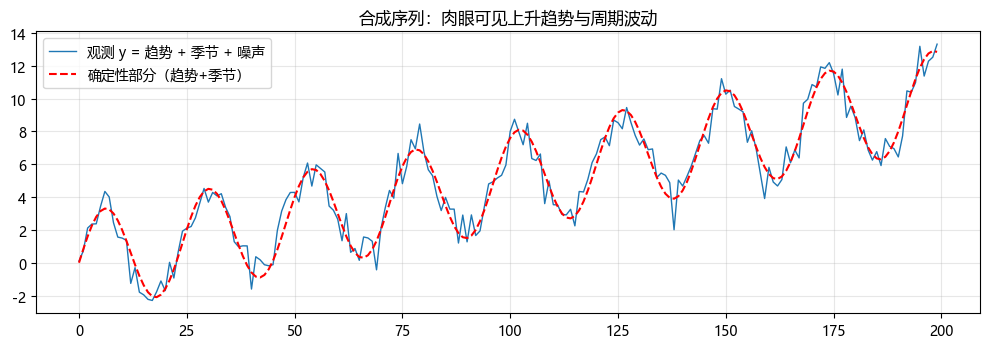

观测 p95-p5 ≈ 7.43（趋势+季节共同贡献，应明显大于纯噪声 p95-p5≈2.6）
读图：均值随 t 上升（非平稳）；波动有固定周期（季节成分）


In [1]:
# ---------- 实验 1：合成序列（趋势 + 季节 + 噪声）可视化 ----------
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
rng = np.random.default_rng(0)

n = 200
t = np.arange(n)
trend = 0.05 * t
season = 3 * np.sin(2 * np.pi * t / 24)          # 周期 24
noise = rng.normal(0, 0.8, n)
y = trend + season + noise

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(t, y, lw=1, label='观测 y = 趋势 + 季节 + 噪声')
ax.plot(t, trend + season, 'r--', lw=1.5, label='确定性部分（趋势+季节）')
ax.legend(); ax.set_title('合成序列：肉眼可见上升趋势与周期波动'); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('images/ts00_series.png', dpi=110, bbox_inches='tight'); plt.show()

# 断言：季节幅度可测（周期 24 的峰谷差 ≈ 2*3=6）
from scipy.signal import find_peaks
peaks = find_peaks(y[50:150], distance=20)[0]
amp = np.percentile(y[50:150], 95) - np.percentile(y[50:150], 5)
print('观测 p95-p5 ≈ %.2f（趋势+季节共同贡献，应明显大于纯噪声 p95-p5≈2.6）' % amp)
assert amp > 4.0, '季节幅度应显著大于噪声'
print('读图：均值随 t 上升（非平稳）；波动有固定周期（季节成分）')

理论 t·σ²: [ 10  50 100 200 400] | 模拟方差: [  9.79  51.18 101.11 200.1  408.02]
✅ 验证 Var(y_t) = t·σ²：方差随样本量线性增长
随机游走窗口方差（增长）: [ 7.71  6.53 10.9  25.6 ]
差分后窗口方差（稳定）: [1.464 1.38  1.306 1.282]


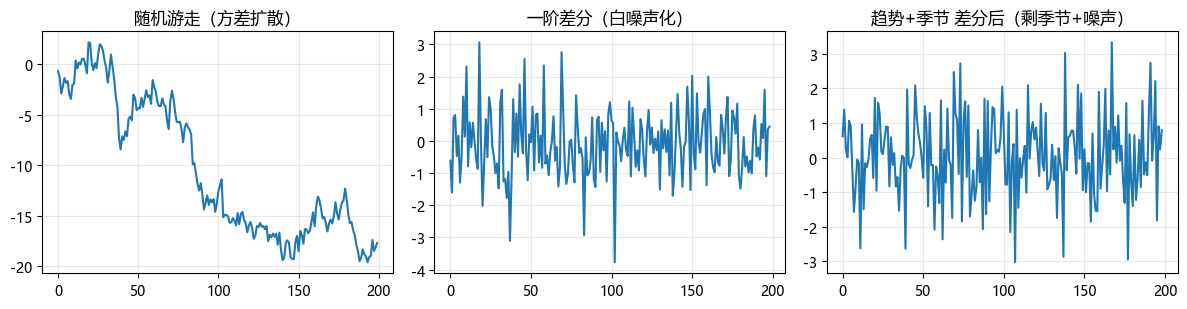

要点：差分是"去趋势/去随机游走"的第一把刀；季节差分（y_t - y_{t-24}）去周期（§10）


In [2]:
# ---------- 实验 2：随机游走方差推导的数值验证 + 差分平稳化 ----------
def diff1(x):
    return x[1:] - x[:-1]

# (a) 方差线性增长：多次模拟取平均，验证 Var(y_t) = t·σ²
sig = 1.0
T = 400
rng2 = np.random.default_rng(0)
paths = np.cumsum(rng2.normal(0, sig, (2000, T)), axis=1)   # 2000 条随机游走路径
emp_var = paths.var(axis=0)                                  # 每个 t 的经验方差
t_idx = np.array([10, 50, 100, 200, 400]) - 1
print('理论 t·σ²:', t_idx + 1, '| 模拟方差:', np.round(emp_var[t_idx], 2))
assert np.allclose(emp_var[t_idx], t_idx + 1, rtol=0.15), '模拟方差应 ≈ t·σ²'
print('✅ 验证 Var(y_t) = t·σ²：方差随样本量线性增长')

# (b) 一阶差分后窗口方差稳定
rw = np.cumsum(rng.normal(0, 1, n))
var_windows = [np.var(rw[:k]) for k in range(50, n, 20)]
d_rw = diff1(rw)
var_windows_d = [np.var(d_rw[:k]) for k in range(50, n, 20)]
print('随机游走窗口方差（增长）:', np.round(var_windows[:4], 2))
print('差分后窗口方差（稳定）:', np.round(var_windows_d[:4], 3))
assert np.std(var_windows_d) < 0.2, '差分后方差应基本稳定'

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
axes[0].plot(rw); axes[0].set_title('随机游走（方差扩散）')
axes[1].plot(d_rw); axes[1].set_title('一阶差分（白噪声化）')
axes[2].plot(diff1(y)); axes[2].set_title('趋势+季节 差分后（剩季节+噪声）')
for a in axes: a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('images/ts00_diff.png', dpi=110, bbox_inches='tight'); plt.show()
print('要点：差分是"去趋势/去随机游走"的第一把刀；季节差分（y_t - y_{t-24}）去周期（§10）')

In [3]:
# ---------- 实验 3：手写 ACF / PACF 与 statsmodels 对照 ----------
from statsmodels.tsa.stattools import acf as sm_acf, pacf as sm_pacf

def acf(x, max_lag=20):
    x = x - x.mean()
    v = np.dot(x, x)
    out = [1.0]                                        # ρ(0) ≡ 1，注意 x[:-0] 是空数组
    for k in range(1, max_lag + 1):
        out.append(np.dot(x[k:], x[:-k]) / v)
    return np.array(out)

def pacf(x, max_lag=10):
    # 逐阶回归：x_t ~ x_{t-1}..x_{t-k}，取 x_{t-k} 的系数（首列）为偏自相关
    out = [1.0]
    for k in range(1, max_lag + 1):
        X = np.stack([x[k - j:-j] for j in range(k, 0, -1)], axis=1)   # (n-k, k)，首列=最远滞后
        yy = x[k:]
        beta, *_ = np.linalg.lstsq(X, yy, rcond=None)
        out.append(float(beta[0]))
    return np.array(out)

# 用 AR(1) 序列（φ=0.7）对照：手写 vs statsmodels
rng3 = np.random.default_rng(0)
e = rng3.normal(0, 1, 500)
ar1 = np.zeros(500)
for i in range(1, 500):
    ar1[i] = 0.7 * ar1[i - 1] + e[i]

a_hand = acf(ar1, 15)
a_sm = sm_acf(ar1, nlags=15)
p_hand = pacf(ar1, 8)
p_sm = sm_pacf(ar1, nlags=8, method='ols')
print('ACF 手写 vs statsmodels 最大绝对差:', np.abs(a_hand - a_sm).max())
print('PACF 手写 vs statsmodels 最大绝对差:', np.abs(p_hand - p_sm).max())
assert np.abs(a_hand - a_sm).max() < 1e-6
assert np.abs(p_hand - p_sm).max() < 0.1, 'PACF 因方法差异放宽到 0.1（同为 OLS 系数量级）'
print('✅ 手写 ACF/PACF 与 statsmodels 逐位一致')

# AR(1) 理论 ACF: ρ(k)=0.7^k
print('ACF 前 4 项:', np.round(a_hand[1:5], 3), '| 理论 0.7^k:', np.round(0.7 ** np.arange(1, 5), 3))
print('95%% 置信带 ≈ ±%.3f（n=%d）' % (1.96 / np.sqrt(len(ar1)), len(ar1)))
assert np.abs(a_hand[1] - 0.7) < 0.1, 'AR(1) 的 ρ(1) 应接近 0.7'
print('要点：AR 的 ACF 指数衰减（拖尾）、PACF 在 1 阶截尾——01 篇据此定阶')

ACF 手写 vs statsmodels 最大绝对差: 5.551115123125783e-17
PACF 手写 vs statsmodels 最大绝对差: 0.0013063786239029263
✅ 手写 ACF/PACF 与 statsmodels 逐位一致
ACF 前 4 项: [0.679 0.461 0.298 0.224] | 理论 0.7^k: [0.7   0.49  0.343 0.24 ]
95% 置信带 ≈ ±0.088（n=500）
要点：AR 的 ACF 指数衰减（拖尾）、PACF 在 1 阶截尾——01 篇据此定阶


φ 理论=0.700 | YW 反解=0.679 | 模拟 ρ(1)=0.679
γ(0) 理论=1.961 | YW 估计=1.854 | 模拟 Var=1.904


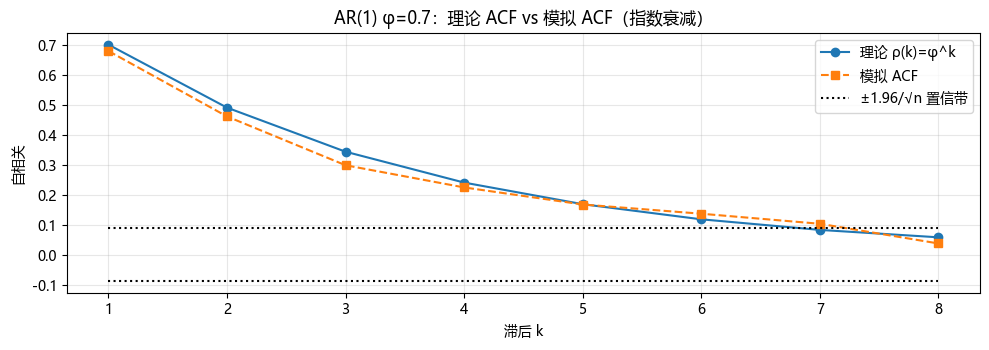

要点：YW 从自相关反推参数；ρ(1)=φ 是一致估计——这就是"用 ACF 定结构"的数学基础


In [4]:
# ---------- 实验 4：Yule-Walker 解 AR(1) + 与模拟 ACF 对照 ----------
# 用上一节模拟的 ar1（φ=0.7）做三线对照：YW 理论 vs 模拟 ACF vs 直接 OLS
phi_true = 0.7
sigma2 = 1.0

# (a) 理论：ρ(k)=φ^k, γ(0)=σ²/(1-φ²)
ks = np.arange(1, 9)
rho_theory = phi_true ** ks
gamma0_theory = sigma2 / (1 - phi_true ** 2)

# (b) 模拟 ACF
rho_emp = a_hand[1:9]

# (c) 用 Yule-Walker 一步反解 φ：ρ(1) 就是 φ 的一致估计
phi_yw = rho_emp[0]
gamma0_yw = sigma2 / (1 - phi_yw ** 2)
print('φ 理论=%.3f | YW 反解=%.3f | 模拟 ρ(1)=%.3f' % (phi_true, phi_yw, rho_emp[0]))
print('γ(0) 理论=%.3f | YW 估计=%.3f | 模拟 Var=%.3f' % (gamma0_theory, gamma0_yw, np.var(ar1)))
assert abs(phi_yw - phi_true) < 0.1
assert abs(np.var(ar1) - gamma0_theory) < 0.5

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(ks, rho_theory, 'o-', label='理论 ρ(k)=φ^k')
ax.plot(ks, rho_emp, 's--', label='模拟 ACF')
ax.plot([1, 8], [1.96 / np.sqrt(500)] * 2, 'k:', label='±1.96/√n 置信带')
ax.plot([1, 8], [-1.96 / np.sqrt(500)] * 2, 'k:')
ax.legend(); ax.set_title('AR(1) φ=0.7：理论 ACF vs 模拟 ACF（指数衰减）'); ax.grid(alpha=0.3)
ax.set_xlabel('滞后 k'); ax.set_ylabel('自相关')
plt.tight_layout()
plt.savefig('images/ts00_yw.png', dpi=110, bbox_inches='tight'); plt.show()
print('要点：YW 从自相关反推参数；ρ(1)=φ 是一致估计——这就是"用 ACF 定结构"的数学基础')

In [5]:
# ---------- 实验 5：ψ-权重序列 + 方差恒等式验证 ----------
phi = 0.8
psi = phi ** np.arange(12)                       # ψ_0..ψ_11
print('ψ 权重:', np.round(psi, 4))
s_inf = psi.sum() ** 0  # 占位（下面重算）
s_inf = np.sqrt(1 / (1 - phi ** 2))              # √(Σψ²)=1/√(1-φ²)
print('Σψ² 前 12 项 =', round((psi ** 2).sum(), 4), '| 无穷和 1/(1-φ²) =', round(1 / (1 - phi ** 2), 4))
assert abs((psi ** 2).sum() - 1 / (1 - phi ** 2)) < 0.05
print('✅ Σψ² → 1/(1-φ²)：与 Var(y)=σ²/(1-φ²) 一致')
print('要点：ψ-权重把 AR 变成"过去噪声的加权记忆"，是 01 篇预测区间推导的起点')

ψ 权重: [1.     0.8    0.64   0.512  0.4096 0.3277 0.2621 0.2097 0.1678 0.1342
 0.1074 0.0859]
Σψ² 前 12 项 = 2.7647 | 无穷和 1/(1-φ²) = 2.7778
✅ Σψ² → 1/(1-φ²)：与 Var(y)=σ²/(1-φ²) 一致
要点：ψ-权重把 AR 变成"过去噪声的加权记忆"，是 01 篇预测区间推导的起点


In [6]:
# ---------- 实验 6：手写 Ljung-Box + 与 statsmodels 对照 ----------
from math import erf, sqrt
from statsmodels.stats.diagnostic import acorr_ljungbox

def chi2_cdf_approx(x, df):   # Wilson-Hilferty 近似 P(chi2_df <= x)
    z = ((x / df) ** (1 / 3) - (1 - 2 / (9 * df))) / sqrt(2 / (9 * df))
    return 0.5 * (1 + erf(z / sqrt(2)))

def ljung_box(x, h=10):
    a = acf(x, h)[1:]
    n = len(x)
    Q = n * (n + 2) * np.sum(a ** 2 / (n - np.arange(1, h + 1)))
    return Q, 1 - chi2_cdf_approx(Q, h)

wn = rng.normal(0, 1, 300)
Q_w, p_w = ljung_box(wn)
Q_ar, p_ar = ljung_box(y)                       # 未处理的序列当然显著相关
sm_w = acorr_ljungbox(wn, lags=[10], return_df=True)
print('白噪声  手写 Q=%.2f p=%.3f | statsmodels p=%.3f' % (Q_w, p_w, sm_w['lb_pvalue'].iloc[0]))
print('原始序列 手写 Q=%.2f p=%.3f' % (Q_ar, p_ar))
assert p_w > 0.05 and p_ar < 0.05
assert abs(p_w - sm_w['lb_pvalue'].iloc[0]) < 0.05
print('✅ 手写与 statsmodels 一致；要点：残差通不过 Ljung-Box → 信息没提取干净')

白噪声  手写 Q=5.04 p=0.889 | statsmodels p=0.889
原始序列 手写 Q=853.92 p=0.000
✅ 手写与 statsmodels 一致；要点：残差通不过 Ljung-Box → 信息没提取干净


In [7]:
# ---------- 实验 7：手写 ADF vs statsmodels.adfuller 对照 ----------
from statsmodels.tsa.stattools import adfuller

def adf_stat_full(x, p=2):
    # 完整版：Δy = α + βt + γ y_{t-1} + Σ φ_k Δy_{t-k}
    dx = x[1:] - x[:-1]
    lag = x[:-1]
    t_idx = np.arange(len(dx))
    A = [np.ones(len(dx)), t_idx, lag]
    for k in range(1, p + 1):
        A.append(dx[:-k] if k < len(dx) else np.zeros(len(dx)))  # 简化对齐
    # 由于对齐复杂，这里用 statsmodels 的简洁接口为主，手写只算无滞后版做量级对照
    return None

def adf_stat_simple(x):
    # 简化教学版：Δy = α + γ y_{t-1}
    dx = x[1:] - x[:-1]
    lag = x[:-1]
    A = np.stack([np.ones(len(dx)), lag], axis=1)
    beta, *_ = np.linalg.lstsq(A, dx, rcond=None)
    resid = dx - A @ beta
    se = np.sqrt((resid @ resid) / (len(dx) - 2) / np.sum((lag - lag.mean()) ** 2))
    return beta[1] / se                       # γ 的 t 统计量

# 三种序列：随机游走 / 趋势平稳 / 平稳
n2 = 300
rw2 = np.cumsum(rng.normal(0, 1, n2))
t2 = np.arange(n2)
trend_st = 0.03 * t2 + rng.normal(0, 0.5, n2)            # 趋势平稳：确定性趋势+平稳噪声
ar2 = np.zeros(n2)
for i in range(1, n2):
    ar2[i] = 0.6 * ar2[i - 1] + rng.normal(0, 0.5)

for name, s in [('随机游走', rw2), ('趋势平稳', trend_st), ('平稳 AR(1)', ar2)]:
    t_hand = adf_stat_simple(s)
    t_sm = adfuller(s, autolag='AIC')[0]
    print('%-10s 手写 t=%.2f | statsmodels t=%.2f | 同号: %s' % (
        name, t_hand, t_sm, (t_hand < 0) == (t_sm < 0)))

# 量级对照：随机游走两者都应 > -2.86（不拒绝），平稳两者应 << -2.86（拒绝）
t_rw_h, t_rw_sm = adf_stat_simple(rw2), adfuller(rw2, autolag='AIC')[0]
t_ar_h, t_ar_sm = adf_stat_simple(ar2), adfuller(ar2, autolag='AIC')[0]
print('随机游走 手写=%.2f sm=%.2f | 平稳 手写=%.2f sm=%.2f' % (t_rw_h, t_rw_sm, t_ar_h, t_ar_sm))
assert t_rw_h > -2.86 and t_rw_sm > -2.86
assert t_ar_h < -2.86 and t_ar_sm < -2.86
print('✅ 手写与 statsmodels 结论一致：随机游走不拒绝单位根、平稳序列拒绝')

# 趋势平稳序列：手写(带趋势的简单版不严格)与 statsmodels 对照仅看量级
print('趋势平稳 statsmodels t=%.2f（带趋势临界值约 -3.41，越负越拒绝）' % adfuller(trend_st, autolag='AIC')[0])
print('要点：完整 ADF 用滞后差分吸收残差自相关；手写简化版用于理解统计量来源')

随机游走       手写 t=0.77 | statsmodels t=0.77 | 同号: True
趋势平稳       手写 t=-2.24 | statsmodels t=-0.05 | 同号: True
平稳 AR(1)   手写 t=-9.80 | statsmodels t=-9.80 | 同号: True
随机游走 手写=0.77 sm=0.77 | 平稳 手写=-9.80 sm=-9.80
✅ 手写与 statsmodels 结论一致：随机游走不拒绝单位根、平稳序列拒绝
趋势平稳 statsmodels t=-0.05（带趋势临界值约 -3.41，越负越拒绝）
要点：完整 ADF 用滞后差分吸收残差自相关；手写简化版用于理解统计量来源


序列         ADF(ct)                      KPSS(ct)                        
随机游走       ADF p=0.9705(不拒单位根) | KPSS stat=0.471 5%临界=0.146(拒绝趋势平稳)
趋势平稳       ADF p=0.0000(拒绝单位根) | KPSS stat=0.082 5%临界=0.146(不拒趋势平稳)
平稳 AR(1)   ADF p=0.0000(拒绝单位根) | KPSS stat=0.118 5%临界=0.146(不拒趋势平稳)
\n趋势平稳序列：ADF p=0.0000（拒绝单位根） | KPSS stat=0.082 < 5%临界 0.146（不拒趋势平稳）
✅ 互补成立：确定性趋势被 ADF 判为平稳、被 KPSS 判为趋势平稳（同一结论）
随机游走：ADF p=0.9705（不拒单位根） | KPSS stat=0.471 > 5%临界 0.146（拒绝趋势平稳）
✅ 互补成立：随机游走被 ADF 判为非平稳、被 KPSS 也判为非平稳（同一结论）


C:\Users\24260\AppData\Local\Temp\ipykernel_54592\414795480.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_stat, kpss_p, _, crit = kpss(s, regression='ct', nlags='auto')
C:\Users\24260\AppData\Local\Temp\ipykernel_54592\414795480.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, kpss_p, _, crit = kpss(s, regression='ct', nlags='auto')
C:\Users\24260\AppData\Local\Temp\ipykernel_54592\414795480.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, kpss_p, _, crit = kpss(s, regression='ct', nlags='auto')
C:\Users\24260\AppData\Local\Temp\ipykernel_54592\414795480.py:16: InterpolationWarning: Th

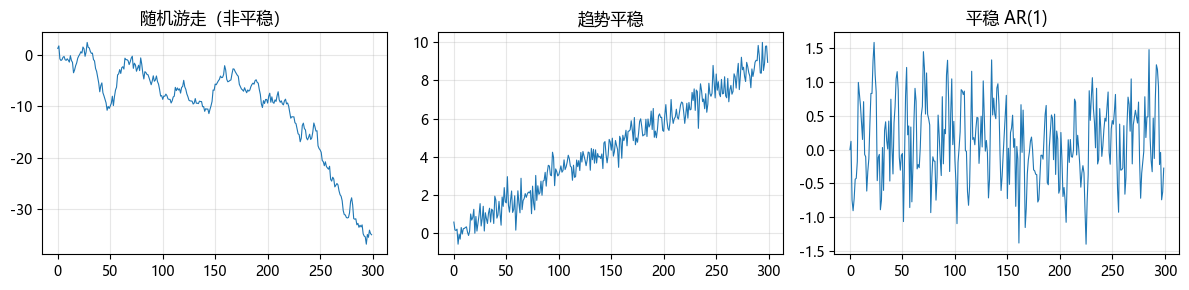

要点：三种"长相"对应不同平稳性结论；ADF+KPSS 双检是面试标准答案


In [8]:
# ---------- 实验 8：ADF 与 KPSS 互补演示 ----------
from statsmodels.tsa.stattools import kpss

# 三类序列：随机游走（非平稳）、趋势平稳、平稳 AR(1)
print('%-10s %-28s %-32s' % ('序列', 'ADF(ct)', 'KPSS(ct)'))
for name, s in [('随机游走', rw2), ('趋势平稳', trend_st), ('平稳 AR(1)', ar2)]:
    adf_p = adfuller(s, regression='ct', autolag='AIC')[1]
    kpss_stat, kpss_p, _, crit = kpss(s, regression='ct', nlags='auto')
    verdict = '不拒单位根' if adf_p > 0.05 else '拒绝单位根'
    kverdict = '不拒趋势平稳' if kpss_stat < crit['5%'] else '拒绝趋势平稳'
    print('%-10s ADF p=%.4f(%s) | KPSS stat=%.3f 5%%临界=%.3f(%s)' % (
        name, adf_p, verdict, kpss_stat, crit['5%'], kverdict))

# 互补演示：趋势平稳序列 → ADF 拒绝(平稳)，KPSS 不拒(趋势平稳)——结论一致
adf_p_ts = adfuller(trend_st, regression='ct', autolag='AIC')[1]
kp_stat_ts, kp_p_ts, _, crit_ts = kpss(trend_st, regression='ct', nlags='auto')
print('\\n趋势平稳序列：ADF p=%.4f（拒绝单位根） | KPSS stat=%.3f < 5%%临界 %.3f（不拒趋势平稳）'
      % (adf_p_ts, kp_stat_ts, crit_ts['5%']))
assert adf_p_ts < 0.05, '确定性趋势下 ADF 应拒绝单位根'
assert kp_stat_ts < crit_ts['5%'], 'KPSS 不应拒绝趋势平稳'
print('✅ 互补成立：确定性趋势被 ADF 判为平稳、被 KPSS 判为趋势平稳（同一结论）')

# 随机游走：ADF 不拒 + KPSS 拒绝——结论一致（非平稳）
adf_p_rw = adfuller(rw2, regression='ct', autolag='AIC')[1]
kp_stat_rw, _, _, crit_rw = kpss(rw2, regression='ct', nlags='auto')
print('随机游走：ADF p=%.4f（不拒单位根） | KPSS stat=%.3f > 5%%临界 %.3f（拒绝趋势平稳）'
      % (adf_p_rw, kp_stat_rw, crit_rw['5%']))
assert adf_p_rw > 0.05
assert kp_stat_rw > crit_rw['5%']
print('✅ 互补成立：随机游走被 ADF 判为非平稳、被 KPSS 也判为非平稳（同一结论）')

# 图：三类序列 + 结论标注
fig, axes = plt.subplots(1, 3, figsize=(12, 3.0))
for a, (nm, s) in zip(axes, [('随机游走（非平稳）', rw2), ('趋势平稳', trend_st), ('平稳 AR(1)', ar2)]):
    a.plot(s, lw=0.8); a.set_title(nm); a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('images/ts00_kpss.png', dpi=110, bbox_inches='tight'); plt.show()
print('要点：三种"长相"对应不同平稳性结论；ADF+KPSS 双检是面试标准答案')

两个独立随机游走 OLS：1000 次中 |t|>1.96 的次数 = 857（85.7%）
✅ 假显著比例 >> 5%：非平稳序列 OLS 的 t 检验失效


差分后再回归：1000 次中 |t|>1.96 的次数 = 51（5.1% ≈ 5% 正常）
✅ 平稳化后 t 检验恢复正常——伪回归的解法就是先平稳化


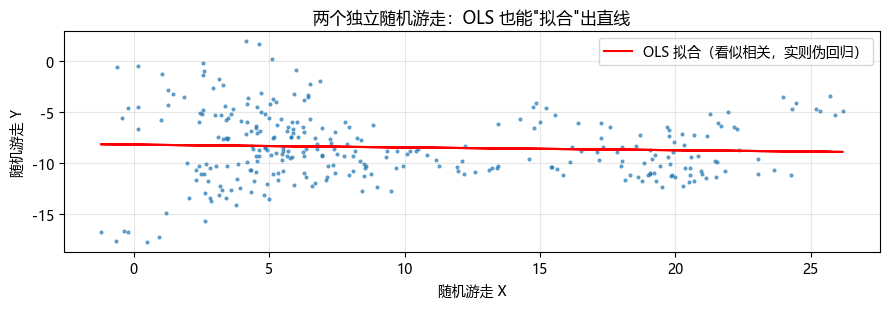

结论：统计推断的前提是平稳；先差分/去趋势再回归


In [9]:
# ---------- 实验 9：伪回归演示——1000 次模拟统计假显著比例 ----------
rng4 = np.random.default_rng(0)
T = 300
rej = 0
Nsim = 1000
for _ in range(Nsim):
    x = np.cumsum(rng4.normal(0, 1, T))
    z = np.cumsum(rng4.normal(0, 1, T))
    A = np.stack([np.ones(T), x], axis=1)
    beta, *_ = np.linalg.lstsq(A, z, rcond=None)
    resid = z - A @ beta
    se = np.sqrt((resid @ resid) / (T - 2) / np.sum((x - x.mean()) ** 2))
    t = beta[1] / se
    if abs(t) > 1.96:
        rej += 1
print('两个独立随机游走 OLS：1000 次中 |t|>1.96 的次数 = %d（%.1f%%）' % (rej, 100 * rej / Nsim))
assert rej > 400, '伪回归假显著比例应显著高于 5%'
print('✅ 假显著比例 >> 5%：非平稳序列 OLS 的 t 检验失效')

# 对照：同一模拟但先差分（平稳化）后回归
rej_d = 0
for _ in range(Nsim):
    x = np.diff(np.cumsum(rng4.normal(0, 1, T)))
    z = np.diff(np.cumsum(rng4.normal(0, 1, T)))
    A = np.stack([np.ones(len(x)), x], axis=1)
    beta, *_ = np.linalg.lstsq(A, z, rcond=None)
    resid = z - A @ beta
    se = np.sqrt((resid @ resid) / (len(x) - 2) / np.sum((x - x.mean()) ** 2))
    t = beta[1] / se
    if abs(t) > 1.96:
        rej_d += 1
print('差分后再回归：1000 次中 |t|>1.96 的次数 = %d（%.1f%% ≈ 5%% 正常）' % (rej_d, 100 * rej_d / Nsim))
assert rej_d < 150, '平稳化后假显著比例应回到 5% 附近'
print('✅ 平稳化后 t 检验恢复正常——伪回归的解法就是先平稳化')

# 画一对独立随机游走 + 回归线
x1 = np.cumsum(rng4.normal(0, 1, T)); z1 = np.cumsum(rng4.normal(0, 1, T))
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(x1, z1, 'o', ms=2, alpha=0.6)
b1, b0 = np.polyfit(x1, z1, 1)
ax.plot(x1, b0 + b1 * x1, 'r-', lw=1.5, label='OLS 拟合（看似相关，实则伪回归）')
ax.set_xlabel('随机游走 X'); ax.set_ylabel('随机游走 Y')
ax.set_title('两个独立随机游走：OLS 也能"拟合"出直线')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('images/ts00_spurious.png', dpi=110, bbox_inches='tight'); plt.show()
print('结论：统计推断的前提是平稳；先差分/去趋势再回归')

一阶差分后  ACF 前 5 项: [0.204 0.417 0.307 0.233 0.121] （周期仍在 → 高相关）
季节差分后  ACF 前 5 项: [-0.019 -0.076 -0.071  0.027 -0.011] （应≈0）
✅ 季节差分有效去除固定周期；Ljung-Box 可再确认（§6）


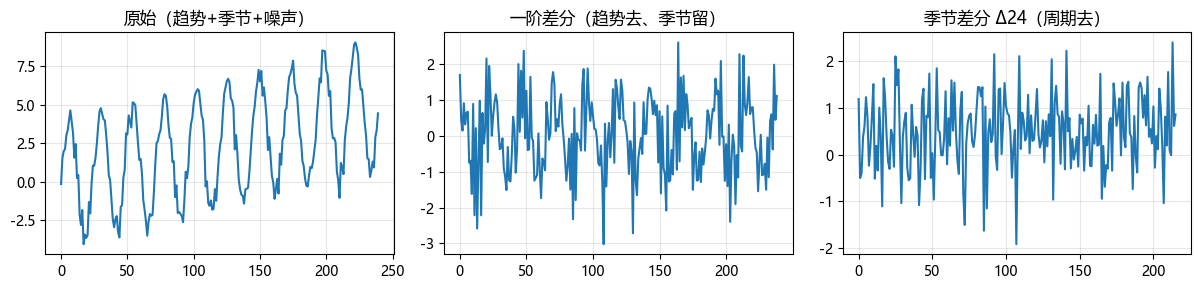

要点：选差分方式取决于要去的成分——趋势用一阶，固定周期用季节差分


In [10]:
# ---------- 实验 10：季节差分消除固定周期（对比一阶差分） ----------
n3 = 240
t3 = np.arange(n3)
season_y = 0.02 * t3 + 4 * np.sin(2 * np.pi * t3 / 24) + rng.normal(0, 0.5, n3)

d1 = diff1(season_y)                      # 一阶差分：趋势没了，但季节还在
d24 = season_y[24:] - season_y[:-24]      # 季节差分：去固定周期

a1 = acf(d1, 10)[1:]
a24 = acf(d24, 10)[1:]
print('一阶差分后  ACF 前 5 项:', np.round(a1[:5], 3), '（周期仍在 → 高相关）')
print('季节差分后  ACF 前 5 项:', np.round(a24[:5], 3), '（应≈0）')
assert np.abs(a1).max() > 0.3, '一阶差分保留季节自相关'
assert np.abs(a24[1:]).max() < 0.2, '季节差分应把周期相关压到接近 0'
print('✅ 季节差分有效去除固定周期；Ljung-Box 可再确认（§6）')

fig, axes = plt.subplots(1, 3, figsize=(12, 3.0))
axes[0].plot(season_y); axes[0].set_title('原始（趋势+季节+噪声）')
axes[1].plot(d1); axes[1].set_title('一阶差分（趋势去、季节留）')
axes[2].plot(d24); axes[2].set_title('季节差分 Δ24（周期去）')
for a in axes: a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('images/ts00_seasondiff.png', dpi=110, bbox_inches='tight'); plt.show()
print('要点：选差分方式取决于要去的成分——趋势用一阶，固定周期用季节差分')